# 🌾 Agriculture Vision — Multi-Label Field Anomaly Classifier

Classifies aerial farmland images (RGB, 512×512) into agricultural patterns using **MobileNetV2 transfer learning**.
Each image can contain several patterns at once, so this is a **multi-label** problem (sigmoid outputs, not softmax).

**Pipeline:** download → extract → build label table → official splits → `tf.data` (cache + augmentation) → train head → fine-tune → tune per-class thresholds on validation → evaluate once on test → save.

**Tips**
- Use a **GPU runtime** (Runtime → Change runtime type → T4). On CPU, one epoch took ~6 minutes.
- Every heavy step is cached or skipped if already done, so you can safely *Run all* after a reconnect.
- Dataset: Agriculture-Vision (Chiu et al., CVPR 2020). Read its Terms of Use before any commercial use.

## 1. Setup

In [2]:
import os, json, shutil, subprocess, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, f1_score

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from google.colab import drive
drive.mount("/content/drive")

# ---- Paths ----
PROJECT_DIR = Path("/content/drive/MyDrive/AgricultureAI")   # persists across sessions
MODEL_DIR   = PROJECT_DIR / "models"
DATA_DIR    = Path("/content/agriculture_dataset")            # local disk = fast I/O
DATA_ROOT   = DATA_DIR / "extracted" / "data2017_miniscale"
for d in (MODEL_DIR, DATA_DIR): d.mkdir(parents=True, exist_ok=True)

# ---- Config ----
SEED = 42
IMG_SIZE, BATCH_SIZE = 224, 32
MIN_POSITIVES = 250        # keep only classes with at least this many positive images
HEAD_EPOCHS, FT_EPOCHS = 5, 10
FINE_TUNE_LAYERS = 30      # last N MobileNetV2 layers to unfreeze
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__, "| GPU:", gpus or "none (training will be slow)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download & extract the dataset (skipped if already done)

In [3]:
S3 = "s3://intelinair-data-releases/agriculture-vision/cvpr_paper_2020"
ARCHIVE = DATA_DIR / "data2017_miniscale.tar.gz"
SPLITS  = DATA_DIR / "data2017_splits.json"
TERMS   = DATA_DIR / "dataset_terms.pdf"

if not shutil.which("aws"):
    subprocess.run(["pip", "install", "-q", "awscli"], check=True)

def s3_get(key, dest):
    if dest.exists():
        print("already have", dest.name); return
    subprocess.run(["aws", "s3", "cp", "--no-sign-request", "--no-progress", f"{S3}/{key}", str(dest)], check=True)
    print("downloaded", dest.name)

s3_get("Dataset/data2017_miniscale.tar.gz", ARCHIVE)   # ~1.8 GB
s3_get("Dataset/data2017_splits.json", SPLITS)
s3_get("Agriculture-Vision Dataset Terms of Use.pdf", TERMS)

if not DATA_ROOT.exists():
    (DATA_DIR / "extracted").mkdir(exist_ok=True)
    subprocess.run(["tar", "-xzf", str(ARCHIVE), "-C", str(DATA_DIR / "extracted")], check=True)
    print("extracted")
else:
    print("already extracted")

RGB_DIR, LABEL_DIR = DATA_ROOT / "field_images" / "rgb", DATA_ROOT / "field_labels"
ALL_CLASSES = sorted(p.name for p in LABEL_DIR.iterdir() if p.is_dir())
print("\nRGB images:", len(list(RGB_DIR.glob("*.jpg"))), "| label classes:", ALL_CLASSES)

downloaded data2017_miniscale.tar.gz
downloaded data2017_splits.json
downloaded dataset_terms.pdf
extracted

RGB images: 8345 | label classes: ['double_plant', 'drydown', 'endrow', 'nutrient_deficiency', 'planter_skip', 'storm_damage', 'water', 'waterway', 'weed_cluster']


## 3. Build the label table

Each label is a 512×512 mask folder per class; an image is **positive** for a class if its mask has any non-zero pixel.
The table is cached to Google Drive, so this (the slowest preprocessing step) only runs once.

  0%|          | 0/8345 [00:00<?, ?it/s]

Built and cached labels: (8345, 10)

Positive images per class:
 drydown                4232
double_plant           1995
weed_cluster           1907
planter_skip            306
endrow                  129
water                    56
storm_damage              2
nutrient_deficiency       0
waterway                  0

Training on: ['drydown', 'double_plant', 'weed_cluster', 'planter_skip']


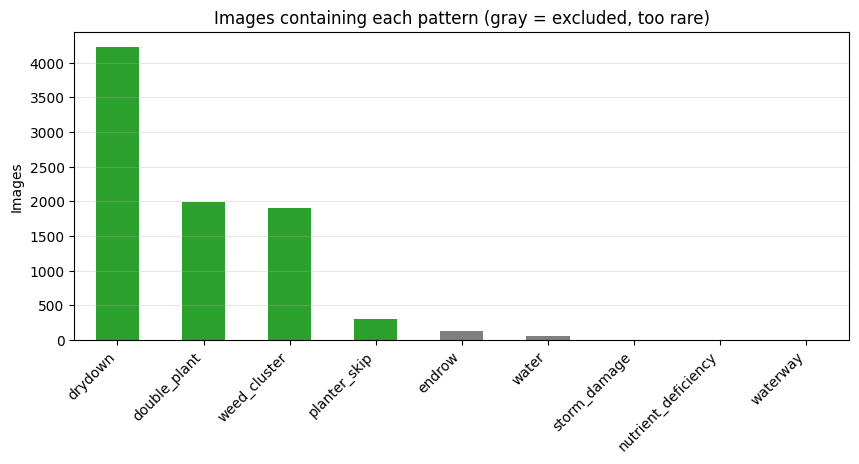

In [4]:
LABELS_CSV = PROJECT_DIR / "labels.csv"

def image_labels(name):
    stem = Path(name).stem
    row = {"image": name}
    for c in ALL_CLASSES:
        row[c] = int(np.any(np.array(Image.open(LABEL_DIR / c / f"{stem}.png"))))
    return row

if LABELS_CSV.exists():
    df = pd.read_csv(LABELS_CSV)
    print("Loaded cached labels:", df.shape)
else:
    names = sorted(p.name for p in RGB_DIR.glob("*.jpg"))
    with ThreadPoolExecutor(8) as ex:
        df = pd.DataFrame(list(tqdm(ex.map(image_labels, names), total=len(names))))
    df.to_csv(LABELS_CSV, index=False)
    print("Built and cached labels:", df.shape)

counts = df[ALL_CLASSES].sum().sort_values(ascending=False)
print("\nPositive images per class:\n", counts.to_string())

# Data-driven class selection: drop classes too rare to learn (e.g. 0 positives for waterway, 2 for storm_damage)
CLASSES = counts[counts >= MIN_POSITIVES].index.tolist()
print("\nTraining on:", CLASSES)

counts.plot(kind="bar", figsize=(10, 4), color=["tab:green" if c in CLASSES else "tab:gray" for c in counts.index])
plt.title("Images containing each pattern (gray = excluded, too rare)")
plt.ylabel("Images"); plt.xticks(rotation=45, ha="right"); plt.grid(axis="y", alpha=.3); plt.show()

### Quick look: one positive example per class (mask overlaid in red)

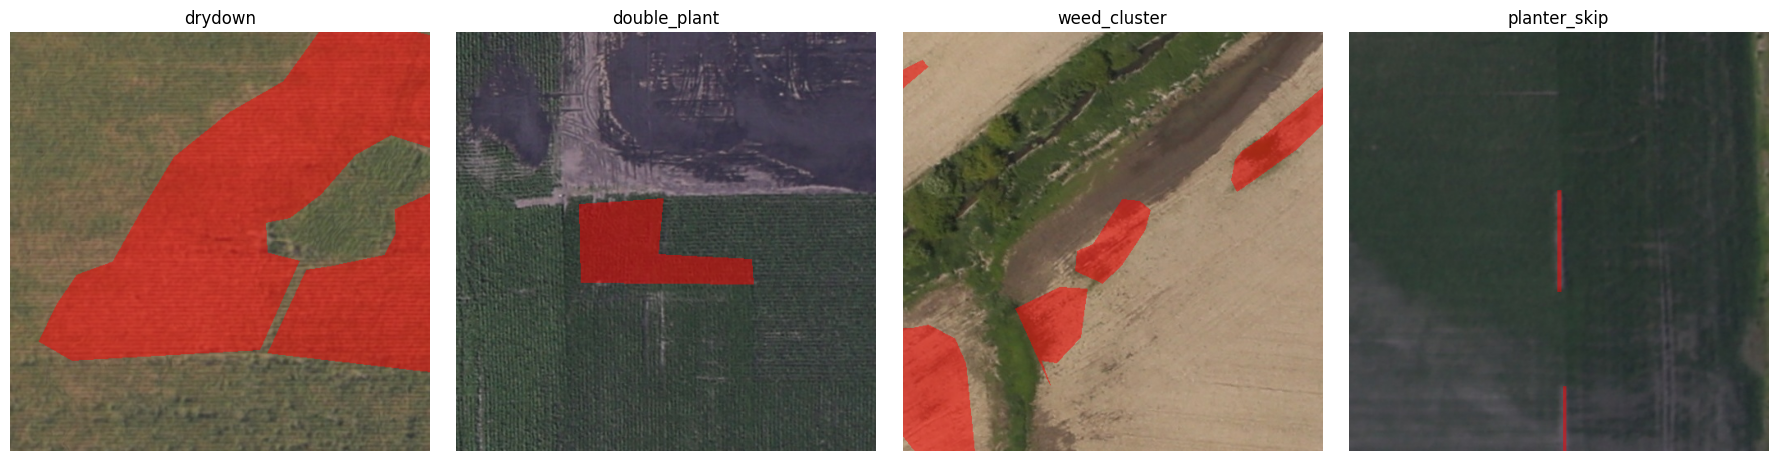

In [5]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4.5 * len(CLASSES), 4.5))
for ax, c in zip(np.atleast_1d(axes), CLASSES):
    name = df[df[c] == 1].sample(1, random_state=SEED).iloc[0]["image"]
    img  = np.array(Image.open(RGB_DIR / name).convert("RGB"))
    mask = np.array(Image.open(LABEL_DIR / c / (Path(name).stem + ".png"))) > 0
    overlay = img.copy(); overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    ax.imshow(overlay); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Official train / val / test splits

The dataset ships with splits defined **per field**, so images from the same field never leak across sets. Keep these official splits.

In [6]:
split_ids = json.load(open(SPLITS))
field_to_split = {fid: s for s, ids in split_ids.items() for fid in ids}

df["split"] = df["image"].str.split("_").str[0].map(field_to_split)
assert df["split"].notna().all(), "some images have no split"
df["image_path"] = df["image"].map(lambda n: str(RGB_DIR / n))

train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))

print(pd.DataFrame({s: d[CLASSES].sum() for s, d in
                    {"train": train_df, "val": val_df, "test": test_df}.items()}).assign(
      ).T.assign(images=[len(train_df), len(val_df), len(test_df)]))

       drydown  double_plant  weed_cluster  planter_skip  images
train     2310          1091          1052           157    4505
val       1000           465           480            47    2048
test       922           439           375           102    1792


## 5. Input pipeline

- Decoded images are **cached in RAM as uint8** (≈1.3 GB total), so JPEG decoding happens once instead of every epoch.
- Training images get **flips + 90° rotations + light brightness jitter** (aerial imagery has no "up", so this is safe).
- `preprocess_input` is applied last, after augmentation.

In [7]:
def load_image(path, labels):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return tf.cast(tf.round(img), tf.uint8), labels

def augment(img, labels):
    img = tf.cast(img, tf.float32)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.clip_by_value(tf.image.random_brightness(img, 25.0), 0.0, 255.0)
    return img, labels

def prep(img, labels):
    return preprocess_input(tf.cast(img, tf.float32)), labels

def make_ds(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["image_path"].values, frame[CLASSES].values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.map(prep, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

x, y = next(iter(train_ds))
print("Batch:", x.shape, y.shape, "| classes:", CLASSES)

Batch: (32, 224, 224, 3) (32, 4) | classes: ['drydown', 'double_plant', 'weed_cluster', 'planter_skip']


## 6. Model

Frozen MobileNetV2 backbone + pooling + dropout + one sigmoid unit per class.

Rare classes (`planter_skip`) are easily ignored, so the loss up-weights positives by **√(negatives / positives)** per class.
The square root is a gentle correction; the full ratio tends to destabilise training.

In [8]:
pos = train_df[CLASSES].sum().values.astype("float32")
POS_WEIGHT = np.sqrt((len(train_df) - pos) / pos).astype("float32")
print(dict(zip(CLASSES, POS_WEIGHT.round(2))))

def weighted_bce(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    loss = -(POS_WEIGHT * y_true * tf.math.log(y_pred) + (1 - y_true) * tf.math.log(1 - y_pred))
    return tf.reduce_mean(loss, axis=-1)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False

inputs  = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x       = base_model(inputs, training=False)          # keep BatchNorm in inference mode
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="sigmoid")(x)
model   = models.Model(inputs, outputs)

def compile_model(lr):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss=weighted_bce,
        metrics=[tf.keras.metrics.AUC(name="auc", multi_label=True, num_labels=len(CLASSES)),
                 tf.keras.metrics.AUC(name="pr_auc", curve="PR", multi_label=True, num_labels=len(CLASSES))])

def make_callbacks(ckpt_name):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.3, patience=1, min_lr=1e-7),
        tf.keras.callbacks.ModelCheckpoint(str(MODEL_DIR / ckpt_name), monitor="val_auc", mode="max", save_best_only=True),
    ]

model.summary(show_trainable=False)

{'drydown': np.float32(0.97), 'double_plant': np.float32(1.77), 'weed_cluster': np.float32(1.81), 'planter_skip': np.float32(5.26)}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Train — phase 1: classifier head only

In [9]:
compile_model(1e-3)
head_history = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
                         callbacks=make_callbacks("phase1_head.keras"))

Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 67s 263ms/step - auc: 0.8635 - loss: 0.4421 - pr_auc: 0.6126 - val_auc: 0.9218 - val_loss: 0.3215 - val_pr_auc: 0.6769 - learning_rate: 0.0010
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 29s 59ms/step - auc: 0.9364 - loss: 0.3067 - pr_auc: 0.7508 - val_auc: 0.9282 - val_loss: 0.2964 - val_pr_auc: 0.6937 - learning_rate: 0.0010
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - auc: 0.9426 - loss: 0.2831 - pr_auc: 0.7739 - val_auc: 0.9328 - val_loss: 0.2850 - val_pr_auc: 0.7039 - learning_rate: 0.0010
Epoch 4/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - auc: 0.9514 - loss: 0.2644 - pr_auc: 0.7871 - val_auc: 0.9345 - val_loss: 0.2788 - val_pr_auc: 0.7181 - learning_rate: 0.0010
Epoch 5/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - auc: 0.9551 - loss: 0.2555 - pr_auc: 0.8021 - val_auc: 0.9345 - val_loss: 0.2744 - val_pr_auc: 0.7268 - learning_rate: 0.0010


## 8. Train — phase 2: fine-tune the top of the backbone

Unfreeze the last 30 layers at a much lower learning rate. BatchNorm layers stay frozen, which is the standard recipe for small datasets.

In [10]:
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
print("Trainable backbone layers:", sum(l.trainable for l in base_model.layers))

compile_model(3e-5)   # must re-compile after changing trainable flags
ft_history = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS,
                       callbacks=make_callbacks("phase2_finetuned.keras"))

Trainable backbone layers: 19
Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 42s 144ms/step - auc: 0.9507 - loss: 0.2588 - pr_auc: 0.7903 - val_auc: 0.9417 - val_loss: 0.2644 - val_pr_auc: 0.7270 - learning_rate: 3.0000e-05
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - auc: 0.9632 - loss: 0.2220 - pr_auc: 0.8291 - val_auc: 0.9398 - val_loss: 0.2738 - val_pr_auc: 0.7461 - learning_rate: 3.0000e-05
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - auc: 0.9743 - loss: 0.1912 - pr_auc: 0.8627 - val_auc: 0.9451 - val_loss: 0.2523 - val_pr_auc: 0.7583 - learning_rate: 9.0000e-06
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - auc: 0.9751 - loss: 0.1837 - pr_auc: 0.8705 - val_auc: 0.9450 - val_loss: 0.2503 - val_pr_auc: 0.7620 - learning_rate: 9.0000e-06
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - auc: 0.9795 - loss: 0.1718 - pr_auc: 0.8806 - val_auc: 0.9430 - val_loss: 0.2560 - val_pr_auc: 0.7603 - learning_rate: 2.7000e-06
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 8

### Training curves (both phases)

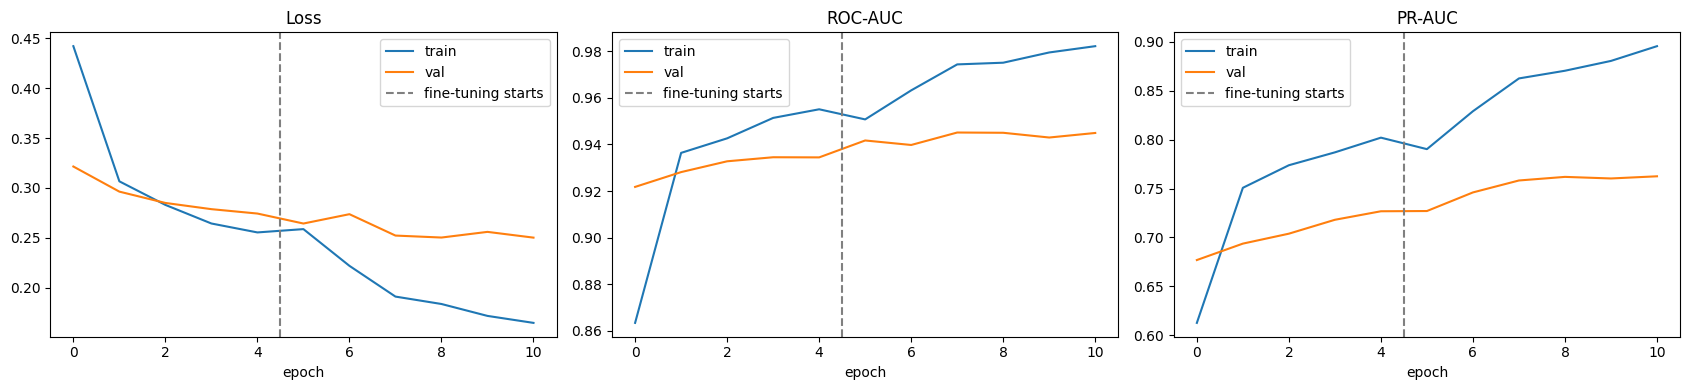

In [11]:
def merged(key):
    return head_history.history[key] + ft_history.history[key]

n_head = len(head_history.history["loss"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (key, title) in zip(axes, [("loss", "Loss"), ("auc", "ROC-AUC"), ("pr_auc", "PR-AUC")]):
    ax.plot(merged(key), label="train"); ax.plot(merged("val_" + key), label="val")
    ax.axvline(n_head - 0.5, color="gray", ls="--", label="fine-tuning starts")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Tune per-class thresholds on **validation**

A fixed 0.5 cut-off is a poor fit for rare classes. For each class we pick the threshold that maximises F1 on the validation set.
The test set is *not* used for this, so the final test score stays honest.

In [12]:
val_prob = model.predict(val_ds, verbose=0)
y_val = val_df[CLASSES].values

grid = np.arange(0.05, 0.96, 0.01)
thresholds = {}
for i, c in enumerate(CLASSES):
    f1s = [f1_score(y_val[:, i], val_prob[:, i] >= t, zero_division=0) for t in grid]
    thresholds[c] = round(float(grid[int(np.argmax(f1s))]), 2)
print("Tuned thresholds:", thresholds)

Tuned thresholds: {'drydown': 0.61, 'double_plant': 0.67, 'weed_cluster': 0.62, 'planter_skip': 0.58}


## 10. Final evaluation on the test set (run once)

In [13]:
test_prob = model.predict(test_ds, verbose=0)
y_test = test_df[CLASSES].values
thr = np.array([thresholds[c] for c in CLASSES])

pred_default = (test_prob >= 0.5).astype(int)
pred_tuned   = (test_prob >= thr).astype(int)

print("=== Threshold 0.5 ===")
print(classification_report(y_test, pred_default, target_names=CLASSES, zero_division=0))
print("=== Tuned thresholds ===")
print(classification_report(y_test, pred_tuned, target_names=CLASSES, zero_division=0))

summary = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test[:, i], test_prob[:, i]) for i in range(len(CLASSES))],
    "PR-AUC":  [average_precision_score(y_test[:, i], test_prob[:, i]) for i in range(len(CLASSES))],
    "F1@0.5":  [f1_score(y_test[:, i], pred_default[:, i], zero_division=0) for i in range(len(CLASSES))],
    "F1@tuned": [f1_score(y_test[:, i], pred_tuned[:, i], zero_division=0) for i in range(len(CLASSES))],
}, index=CLASSES).round(3)
summary.loc["MEAN"] = summary.mean().round(3)
summary

=== Threshold 0.5 ===
              precision    recall  f1-score   support

     drydown       0.98      0.91      0.94       922
double_plant       0.65      0.89      0.75       439
weed_cluster       0.57      0.75      0.65       375
planter_skip       0.55      0.56      0.55       102

   micro avg       0.76      0.85      0.81      1838
   macro avg       0.69      0.78      0.72      1838
weighted avg       0.79      0.85      0.82      1838
 samples avg       0.79      0.85      0.81      1838

=== Tuned thresholds ===
              precision    recall  f1-score   support

     drydown       0.98      0.91      0.94       922
double_plant       0.69      0.81      0.74       439
weed_cluster       0.60      0.67      0.63       375
planter_skip       0.60      0.51      0.55       102

   micro avg       0.80      0.81      0.81      1838
   macro avg       0.72      0.72      0.72      1838
weighted avg       0.81      0.81      0.81      1838
 samples avg       0.79      0

,ROC-AUC,PR-AUC,F1@0.5,F1@tuned
drydown,0.986,0.989,0.944,0.945
double_plant,0.940,0.809,0.750,0.744
weed_cluster,0.898,0.685,0.650,0.633
planter_skip,0.924,0.614,0.553,0.553
MEAN,0.937,0.774,0.724,0.719


### Sample test predictions

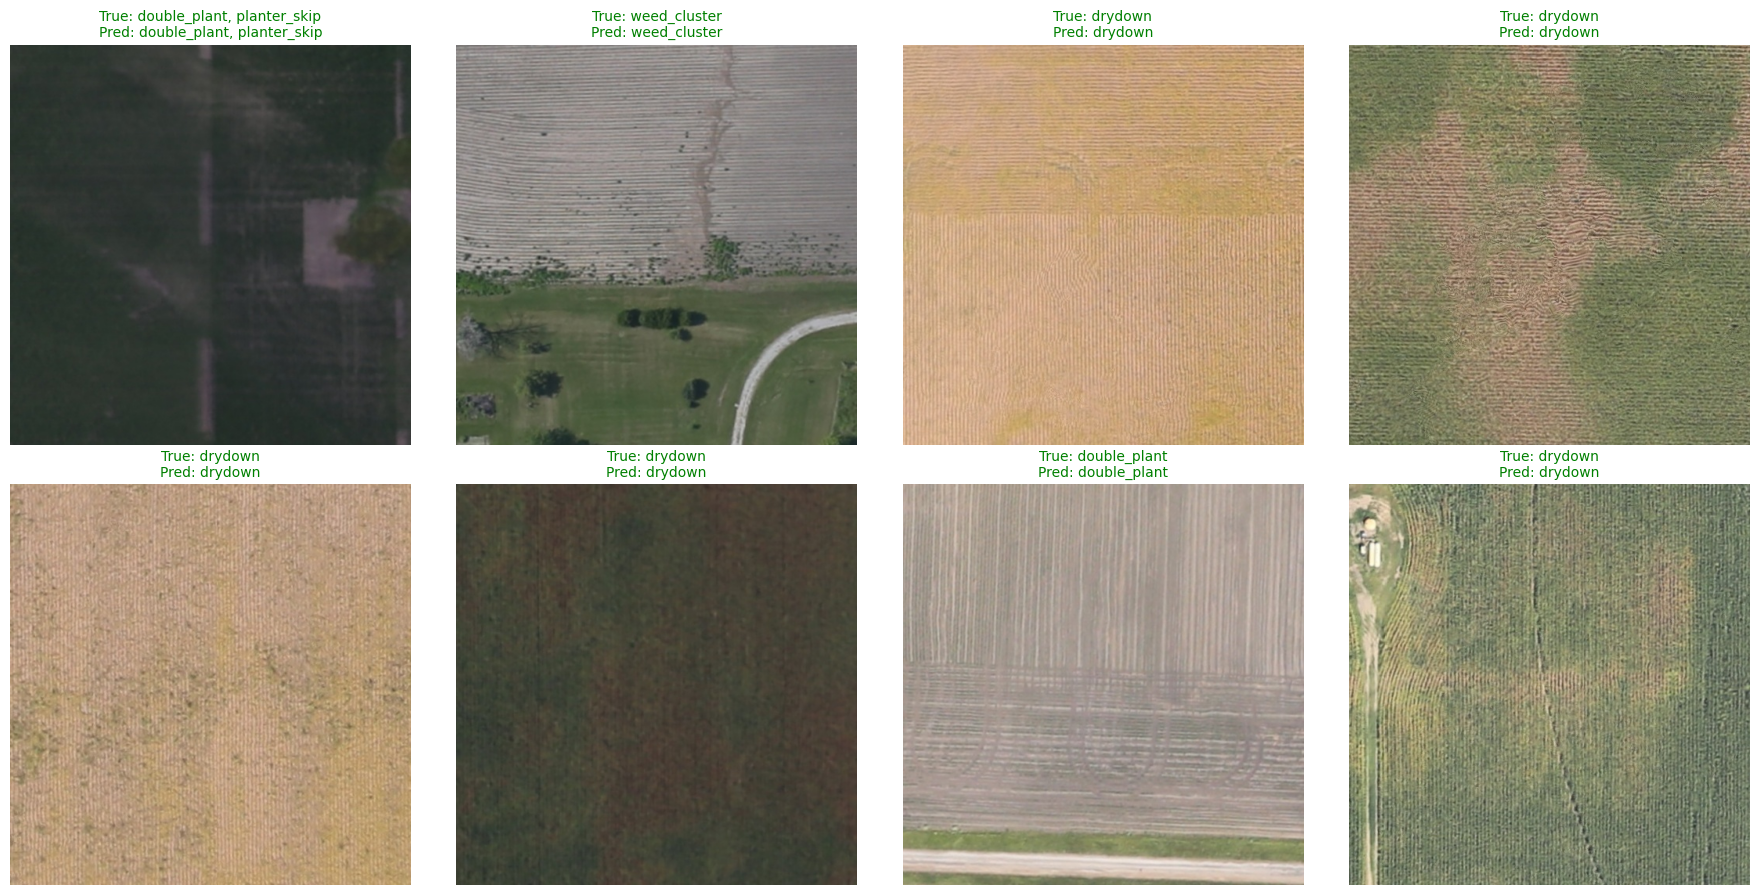

In [14]:
sample = test_df.sample(8, random_state=SEED).index
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, idx in zip(axes.flat, sample):
    ax.imshow(Image.open(test_df.loc[idx, "image_path"]).convert("RGB")); ax.axis("off")
    truth = [c for c in CLASSES if test_df.loc[idx, c] == 1] or ["none"]
    pred  = [c for i, c in enumerate(CLASSES) if pred_tuned[idx, i]] or ["none"]
    ax.set_title(f"True: {', '.join(truth)}\nPred: {', '.join(pred)}", fontsize=10,
                 color="green" if set(truth) == set(pred) else "crimson")
plt.tight_layout(); plt.show()

## 11. Save the model and thresholds to Google Drive

In [15]:
model.save(MODEL_DIR / "agriculture_mobilenetv2.keras")
json.dump({"classes": CLASSES, "thresholds": thresholds, "img_size": IMG_SIZE},
          open(MODEL_DIR / "model_config.json", "w"), indent=2)
print("Saved to", MODEL_DIR)

# To reload later (custom loss is only needed for training, so skip compiling):
# model = tf.keras.models.load_model(MODEL_DIR / "agriculture_mobilenetv2.keras", compile=False)

Saved to /content/drive/MyDrive/AgricultureAI/models


## 12. Predict on any image

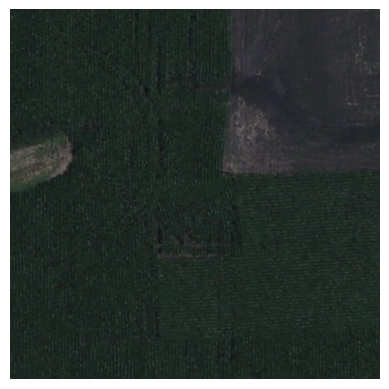

· drydown           0.1%
· double_plant     59.7%
· weed_cluster     30.2%
✔ planter_skip     95.0%


In [16]:
def predict_image(path, show=True):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    probs = model.predict(preprocess_input(img[None]), verbose=0)[0]
    result = {c: {"probability": float(p), "detected": bool(p >= thresholds[c])}
              for c, p in zip(CLASSES, probs)}
    if show:
        plt.imshow(Image.open(path).convert("RGB")); plt.axis("off"); plt.show()
        for c, r in result.items():
            print(f"{'✔' if r['detected'] else '·'} {c:15s} {r['probability'] * 100:5.1f}%")
    return result

# Try it on a test image:
_ = predict_image(test_df.loc[0, "image_path"])

# Or upload your own farmland photo (works best on aerial images similar to the dataset):
# from google.colab import files
# up = files.upload(); _ = predict_image(next(iter(up)))